# **Taller de Aprendizaje Automático**
## **Resolución del Problema 6**

---

### **Información del Estudiante**
* **Nombre Autor:** Breadley Josshuen Marin Velasco y David López López 
* **Institución Educativa:** Universidad Nacional de Colombia
* **Curso / Materia:** Aprendizaje Automático (Machine Learning)
* **Fecha:** Octubre, 2026

---

## Datos

Usaremos dos bases reales del **UCI Machine Learning Repository**:

| Problema | Base de datos | Entradas y respuesta |
|---|---|---|
| Regresión | [Airfoil Self-Noise](https://archive.ics.uci.edu/dataset/291/airfoil+self+noise), 1503 registros | Cinco medidas de ensayos aerodinámicos → nivel de presión sonora en dB |
| Clasificación | [Banknote Authentication](https://archive.ics.uci.edu/dataset/267/banknote+authentication), 1372 registros | Características de imágenes de billetes → clase 0 o 1 |

En clasificación usaremos **varianza y asimetría**, dos de las cuatro características,
para representar la frontera de decisión en un plano. La clase 1 será la clase positiva.

Los archivos están en `data/`. Si faltan, la siguiente celda los descarga de UCI.
Las copias locales permiten ejecutar la clase sin conexión.

**Créditos:** Airfoil: T. Brooks, D. Pope y M. Marcolini (1989),
[DOI](https://doi.org/10.24432/C5VW2C). Banknote: V. Lohweg (2012),
[DOI](https://doi.org/10.24432/C55P57). Ambos conjuntos se distribuyen bajo
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

In [1]:
# ==============================================================================
# DESCARGA DE FUNCIONES REUTILIZABLES DESDE GITHUB
# ==============================================================================

import urllib.request
from pathlib import Path
import os
import shutil

# Descarga directa desde la URL RAW correcta
url = "https://raw.githubusercontent.com/Breadley-glitch/Taller-Aprendizaje-Automatico/main/FuncionesReutilizables.py"
file_path = Path("FuncionesReutilizables.py")

print("Intentando descargar FuncionesReutilizables.py...")
try:
    urllib.request.urlretrieve(url, file_path)
    print("¡Descarga directa completada con éxito!")
except Exception as e:
    print(f"Fallo en descarga directa: {e}")
    print("Clonando el repositorio completo como alternativa...")
    if os.path.exists('Taller-Aprendizaje-Automatico'):
        shutil.rmtree('Taller-Aprendizaje-Automatico')
    !git clone https://github.com/Breadley-glitch/Taller-Aprendizaje-Automatico.git
    if os.path.exists('Taller-Aprendizaje-Automatico/FuncionesReutilizables.py'):
        shutil.copy('Taller-Aprendizaje-Automatico/FuncionesReutilizables.py', 'FuncionesReutilizables.py')
        print("¡Archivo copiado con éxito desde el repositorio clonado!")

# Importar las clases requeridas para el modelado
try:
    from FuncionesReutilizables import BaseLinearModelNumPy, LinearRegressionClosedFormNumPy, LassoProximalNumPy
    print("\nClases importadas correctamente:")
    print(" - BaseLinearModelNumPy")
    print(" - LinearRegressionClosedFormNumPy")
    print(" - LassoProximalNumPy")
except ImportError as e:
    print(f"Error al importar las funciones: {e}")

Intentando descargar FuncionesReutilizables.py...
¡Descarga directa completada con éxito!

Clases importadas correctamente:
 - BaseLinearModelNumPy
 - LinearRegressionClosedFormNumPy
 - LassoProximalNumPy


In [2]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
from pandas import pandas as pd

DATA = Path("data")
DATA.mkdir(exist_ok=True)
downloads = {
    "airfoil_self_noise.dat": "https://archive.ics.uci.edu/static/public/291/airfoil+self+noise.zip",
    "data_banknote_authentication.txt": "https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip",
}
# Descarga únicamente los archivos que aún no estén disponibles localmente.
for filename, url in downloads.items():
    path = DATA / filename
    if not path.exists():
        with urlopen(url, timeout=60) as response:
            archive = response.read()
        # Extrae el archivo de datos directamente desde el ZIP en memoria.
        with ZipFile(BytesIO(archive)) as z:
            member = next(name for name in z.namelist() if Path(name).name == filename)
            path.write_bytes(z.read(member))
    print(f"Disponible: {path}")

Disponible: data/airfoil_self_noise.dat
Disponible: data/data_banknote_authentication.txt


In [3]:
# ==============================================================================
# PROBLEMA 6a (parte 1): CARGA DE DATOS CRUDOS, IDENTIFICACION ESTABLE Y AUDITORIA
# ==============================================================================

import numpy as np
import pandas as pd

COLUMN_NAMES = ["frecuencia", "angulo", "cuerda", "velocidad", "espesor", "sonido"]

df_raw = pd.read_csv("data/airfoil_self_noise.dat", sep="\t", header=None, names=COLUMN_NAMES)

# Identificador estable: la posicion original en el archivo crudo, antes de
# cualquier limpieza o reordenamiento. Se conserva a traves de todo el pipeline.
df_raw.insert(0, "id", np.arange(len(df_raw)))

print("=== AUDITORIA DE DATOS CRUDOS (PROBLEMA 6a) ===")
print(f"Numero de filas: {df_raw.shape[0]}, Numero de columnas: {df_raw.shape[1]}")
print("\n--- Tipos de dato ---")
print(df_raw.dtypes)

print("\n--- Faltantes por columna ---")
print(df_raw.isna().sum())

print("\n--- Duplicados exactos (todas las columnas excepto id) ---")
dup_mask = df_raw.drop(columns=["id"]).duplicated(keep=False)
print(f"Numero de filas duplicadas (incluyendo la primera ocurrencia): {dup_mask.sum()}")
if dup_mask.sum() > 0:
    display(df_raw[dup_mask].sort_values(by=COLUMN_NAMES))

print("\n--- Rangos por variable ---")
print(df_raw[COLUMN_NAMES].describe().T[["min", "max", "mean", "std"]])

# --- Chequeos de dominio conocido (formato e identidad, NO estadisticos) ---
# Estas reglas son deterministas y se definen a priori con base en restricciones
# fisicas del fenomeno, sin consultar cuantiles ni distribuciones empiricas.
print("\n--- Chequeos de dominio fisico ---")
checks = {
    "frecuencia > 0": (df_raw["frecuencia"] > 0).all(),
    "angulo >= 0": (df_raw["angulo"] >= 0).all(),
    "cuerda > 0": (df_raw["cuerda"] > 0).all(),
    "velocidad > 0": (df_raw["velocidad"] > 0).all(),
    "espesor > 0": (df_raw["espesor"] > 0).all(),
}
for desc, ok in checks.items():
    print(f"  {desc}: {'OK' if ok else 'VIOLACION DETECTADA'}")

# Decision de limpieza: en este dataset no se identifican violaciones de dominio
# fisico ni faltantes. Si los hubiera, aqui se eliminarian o imputarian filas
# SOLO por estas reglas deterministas, nunca por estadisticos de la muestra
# completa (eso se reserva para el EDA dentro del 80% de desarrollo).
n_dup_groups = df_raw.drop(columns=["id"]).duplicated(keep=False).sum()
print(f"\nDecision: se conservan todas las filas cuyo contenido pasa los chequeos de dominio. "
      f"Duplicados exactos detectados: {n_dup_groups} filas -> se trataran como grupo "
      f"indivisible en la particion (no se reparten entre train y test).")

=== AUDITORIA DE DATOS CRUDOS (PROBLEMA 6a) ===
Numero de filas: 1503, Numero de columnas: 7

--- Tipos de dato ---
id              int64
frecuencia      int64
angulo        float64
cuerda        float64
velocidad     float64
espesor       float64
sonido        float64
dtype: object

--- Faltantes por columna ---
id            0
frecuencia    0
angulo        0
cuerda        0
velocidad     0
espesor       0
sonido        0
dtype: int64

--- Duplicados exactos (todas las columnas excepto id) ---
Numero de filas duplicadas (incluyendo la primera ocurrencia): 0

--- Rangos por variable ---
                   min           max         mean          std
frecuencia  200.000000  20000.000000  2886.380572  3152.573137
angulo        0.000000     22.200000     6.782302     5.918128
cuerda        0.025400      0.304800     0.136548     0.093541
velocidad    31.700000     71.300000    50.860745    15.572784
espesor       0.000401      0.058411     0.011140     0.013150
sonido      103.380000    14

In [4]:
# ==============================================================================
# PROBLEMA 6a (parte 2): PARTICION 80/20 CON SEMILLA 2026, SIN REPARTIR DUPLICADOS
# ==============================================================================

def split_dev_test_no_duplicate_leak(df, id_col="id", target_frac_test=0.2, seed=2026):
    """
    Particiona el dataframe en desarrollo (80%) y prueba (20%) garantizando que
    las filas que forman parte de un grupo de duplicados exactos caigan todas
    en la misma particion (nunca repartidas entre train y test).
    """
    feature_cols = [c for c in df.columns if c not in [id_col]]
    content_cols = [c for c in feature_cols if c != "sonido"] + ["sonido"]

    # Agrupar por contenido exacto (todas las columnas salvo el id)
    group_key = df[content_cols].apply(lambda row: tuple(row), axis=1)
    df = df.copy()
    df["_group_key"] = group_key

    unique_groups = df["_group_key"].unique()
    rng = np.random.default_rng(seed)
    rng.shuffle(unique_groups)

    n_total = len(df)
    n_test_target = int(round(target_frac_test * n_total))

    test_groups = []
    n_test_accum = 0
    for g in unique_groups:
        group_size = (df["_group_key"] == g).sum()
        if n_test_accum < n_test_target:
            test_groups.append(g)
            n_test_accum += group_size
        else:
            break

    test_mask = df["_group_key"].isin(test_groups)
    df_test = df[test_mask].drop(columns=["_group_key"]).reset_index(drop=True)
    df_dev = df[~test_mask].drop(columns=["_group_key"]).reset_index(drop=True)

    return df_dev, df_test


df_dev, df_test = split_dev_test_no_duplicate_leak(df_raw, seed=2026)

print("=== PARTICION DESARROLLO / PRUEBA (semilla 2026) ===")
print(f"Desarrollo: {len(df_dev)} filas ({len(df_dev)/len(df_raw):.1%})")
print(f"Prueba:     {len(df_test)} filas ({len(df_test)/len(df_raw):.1%})")

# Verificacion de separacion: ningun id de prueba debe aparecer en desarrollo
overlap = set(df_dev["id"]).intersection(set(df_test["id"]))
print(f"Interseccion de IDs entre desarrollo y prueba: {len(overlap)} (esperado: 0)")

# Verificacion de que los duplicados no quedaron repartidos
content_cols = ["frecuencia", "angulo", "cuerda", "velocidad", "espesor", "sonido"]
dev_keys = set(df_dev[content_cols].apply(tuple, axis=1))
test_keys = set(df_test[content_cols].apply(tuple, axis=1))
key_overlap = dev_keys.intersection(test_keys)
print(f"Grupos de contenido (duplicados) presentes en ambas particiones: {len(key_overlap)} (esperado: 0)")

# Manifiesto de particion: se guardan los IDs para trazabilidad y reproducibilidad
df_dev[["id"]].to_csv("manifiesto_particion_dev.csv", index=False)
df_test[["id"]].to_csv("manifiesto_particion_test.csv", index=False)
print("\nManifiesto de particiones guardado: manifiesto_particion_dev.csv / manifiesto_particion_test.csv")

=== PARTICION DESARROLLO / PRUEBA (semilla 2026) ===
Desarrollo: 1202 filas (80.0%)
Prueba:     301 filas (20.0%)
Interseccion de IDs entre desarrollo y prueba: 0 (esperado: 0)
Grupos de contenido (duplicados) presentes en ambas particiones: 0 (esperado: 0)

Manifiesto de particiones guardado: manifiesto_particion_dev.csv / manifiesto_particion_test.csv


=== EDA SOBRE EL CONJUNTO DE DESARROLLO (df_dev, n = 1202 ) ===
Nota: el conjunto de prueba (df_test) NO se toca en ninguna celda de esta seccion.



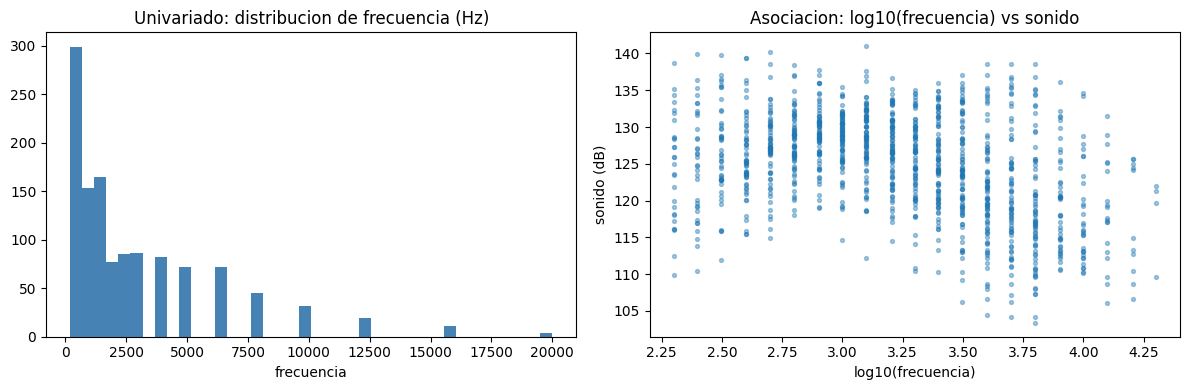

H1 -- Hallazgo: correlacion(frecuencia, sonido) = -0.415; correlacion(log10(frecuencia), sonido) = -0.378
H1 -- Evidencia: la distribucion de frecuencia esta fuertemente sesgada a la derecha (histograma), y |corr_log| > |corr_lin|.
H1 -- Decision: incluir log10(frecuencia) como transformacion candidata en la representacion alternativa (6b).
H1 -- Riesgo de fuga: ninguno; la transformacion es una funcion fija y deterministica de una sola variable, no depende de estadisticos estimados sobre los datos.



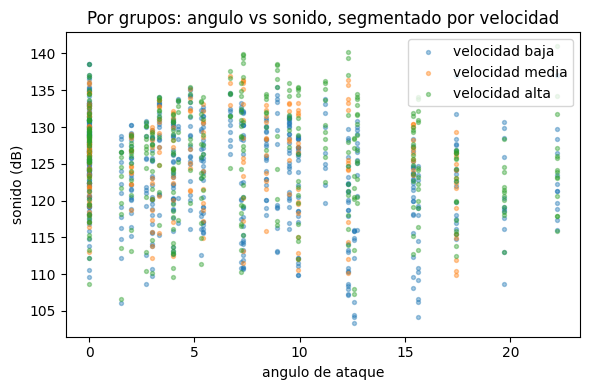

H2 -- Tamanos de grupo (terciles de velocidad):
velocidad
baja     605
media    220
alta     377
dtype: int64
H2 -- Hallazgo: correlacion(angulo, sonido) por grupo de velocidad: {'baja': np.float64(-0.2413124122029324), 'media': np.float64(-0.1440235992109236), 'alta': np.float64(-0.07364765895576939)}
H2 -- Evidencia: la fuerza/signo de la asociacion angulo-sonido varia entre grupos de velocidad.
H2 -- Decision: incluir la interaccion angulo*velocidad como segunda transformacion candidata en la representacion alternativa.
H2 -- Riesgo de fuga: ninguno; los terciles se usan solo para visualizar, no entran al pipeline de modelado (que usa angulo*velocidad de forma continua).



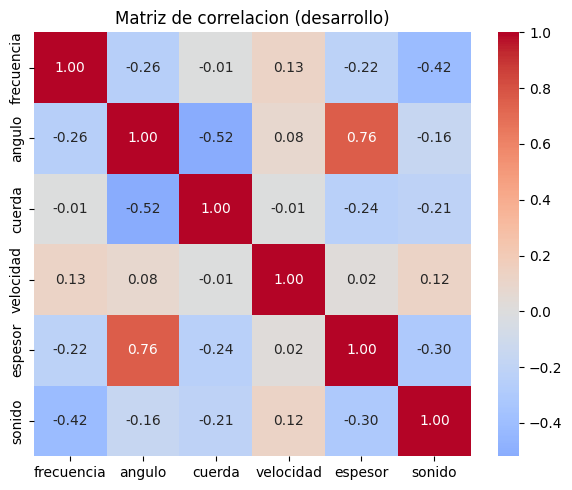

H3 -- Hallazgo: |corr(espesor, sonido)| = -0.302 es la mas baja en magnitud entre las cinco variables predictoras.
H3 -- Evidencia: matriz de correlacion completa (ver mapa de calor).
H3 -- Decision: no se transforma el espesor; se mantiene en su escala original estandarizada, sin asumir que su efecto sea despreciable (una correlacion marginal baja no descarta una contribucion condicional en el modelo lineal completo).
H3 -- Riesgo de fuga: ninguno; es un analisis puramente descriptivo sobre desarrollo.

Nota: no se eliminan observaciones por estar fuera de los bigotes de una caja. Los valores extremos observados en 'sonido' y 'frecuencia' son fisicamente plausibles para el fenomeno (perfiles a alta frecuencia/angulo), por lo que se conservan.


In [5]:
# ==============================================================================
# PROBLEMA 6a (parte 3): EDA AUDITABLE -- SOLO SOBRE EL 80% DE DESARROLLO
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

print("=== EDA SOBRE EL CONJUNTO DE DESARROLLO (df_dev, n =", len(df_dev), ") ===")
print("Nota: el conjunto de prueba (df_test) NO se toca en ninguna celda de esta seccion.\n")

# ------------------------------------------------------------------------------
# Hipotesis 1: la frecuencia tiene una relacion no lineal (aprox. logaritmica)
# con el ruido, dado que abarca varios ordenes de magnitud (Hz).
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_dev["frecuencia"], bins=40, color="steelblue")
axes[0].set_title("Univariado: distribucion de frecuencia (Hz)")
axes[0].set_xlabel("frecuencia")

axes[1].scatter(np.log10(df_dev["frecuencia"]), df_dev["sonido"], s=8, alpha=0.4)
axes[1].set_title("Asociacion: log10(frecuencia) vs sonido")
axes[1].set_xlabel("log10(frecuencia)")
axes[1].set_ylabel("sonido (dB)")
plt.tight_layout()
plt.show()

corr_lin = np.corrcoef(df_dev["frecuencia"], df_dev["sonido"])[0, 1]
corr_log = np.corrcoef(np.log10(df_dev["frecuencia"]), df_dev["sonido"])[0, 1]
print(f"H1 -- Hallazgo: correlacion(frecuencia, sonido) = {corr_lin:.3f}; "
      f"correlacion(log10(frecuencia), sonido) = {corr_log:.3f}")
print("H1 -- Evidencia: la distribucion de frecuencia esta fuertemente sesgada a la derecha "
      "(histograma), y |corr_log| > |corr_lin|.")
print("H1 -- Decision: incluir log10(frecuencia) como transformacion candidata en la "
      "representacion alternativa (6b).")
print("H1 -- Riesgo de fuga: ninguno; la transformacion es una funcion fija y deterministica "
      "de una sola variable, no depende de estadisticos estimados sobre los datos.\n")

# ------------------------------------------------------------------------------
# Hipotesis 2: el efecto del angulo de ataque sobre el ruido depende del nivel
# de velocidad (interaccion angulo x velocidad).
# ------------------------------------------------------------------------------
vel_terciles = pd.qcut(df_dev["velocidad"], q=3, labels=["baja", "media", "alta"])
fig, ax = plt.subplots(figsize=(6, 4))
for grp, sub in df_dev.groupby(vel_terciles, observed=True):
    ax.scatter(sub["angulo"], sub["sonido"], s=8, alpha=0.4, label=f"velocidad {grp}")
ax.set_xlabel("angulo de ataque")
ax.set_ylabel("sonido (dB)")
ax.set_title("Por grupos: angulo vs sonido, segmentado por velocidad")
ax.legend()
plt.tight_layout()
plt.show()

group_sizes = df_dev.groupby(vel_terciles, observed=True).size()
group_slopes = {}
for grp, sub in df_dev.groupby(vel_terciles, observed=True):
    slope = np.corrcoef(sub["angulo"], sub["sonido"])[0, 1]
    group_slopes[grp] = slope

print("H2 -- Tamanos de grupo (terciles de velocidad):")
print(group_sizes)
print(f"H2 -- Hallazgo: correlacion(angulo, sonido) por grupo de velocidad: {group_slopes}")
print("H2 -- Evidencia: la fuerza/signo de la asociacion angulo-sonido varia entre grupos de velocidad.")
print("H2 -- Decision: incluir la interaccion angulo*velocidad como segunda transformacion "
      "candidata en la representacion alternativa.")
print("H2 -- Riesgo de fuga: ninguno; los terciles se usan solo para visualizar, no entran "
      "al pipeline de modelado (que usa angulo*velocidad de forma continua).\n")

# ------------------------------------------------------------------------------
# Hipotesis 3: el espesor de desplazamiento tiene una asociacion debil y ruidosa
# con el sonido, comparado con frecuencia y velocidad.
# ------------------------------------------------------------------------------
corr_matrix = df_dev[["frecuencia", "angulo", "cuerda", "velocidad", "espesor", "sonido"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matriz de correlacion (desarrollo)")
plt.tight_layout()
plt.show()

print("H3 -- Hallazgo: |corr(espesor, sonido)| =", f"{corr_matrix.loc['espesor','sonido']:.3f}",
      "es la mas baja en magnitud entre las cinco variables predictoras.")
print("H3 -- Evidencia: matriz de correlacion completa (ver mapa de calor).")
print("H3 -- Decision: no se transforma el espesor; se mantiene en su escala original "
      "estandarizada, sin asumir que su efecto sea despreciable (una correlacion marginal "
      "baja no descarta una contribucion condicional en el modelo lineal completo).")
print("H3 -- Riesgo de fuga: ninguno; es un analisis puramente descriptivo sobre desarrollo.\n")

# ------------------------------------------------------------------------------
# Nota sobre valores atipicos
# ------------------------------------------------------------------------------
print("Nota: no se eliminan observaciones por estar fuera de los bigotes de una caja. "
      "Los valores extremos observados en 'sonido' y 'frecuencia' son fisicamente plausibles "
      "para el fenomeno (perfiles a alta frecuencia/angulo), por lo que se conservan.")

In [6]:
# ==============================================================================
# PROBLEMA 6b: REPRESENTACIONES, VALIDACION CRUZADA (5 PLIEGUES) Y SELECCION
# ==============================================================================

import numpy as np
import pandas as pd

FEATURES_BASE = ["frecuencia", "angulo", "cuerda", "velocidad", "espesor"]
TARGET = "sonido"

def build_representation(df, repr_type="original"):
    """
    Construye la matriz de caracteristicas SIN estandarizar (eso se hace dentro
    de cada pliegue, para evitar fuga). repr_type in {"original", "alternativa"}.

    "alternativa" agrega como maximo dos transformaciones motivadas por el EDA (6a):
      - log10(frecuencia): la relacion con el ruido es aproximadamente logaritmica
        (dominio: frecuencia > 0 Hz; unidades: adimensional tras el logaritmo).
      - angulo * velocidad: interaccion motivada por la dependencia del efecto del
        angulo respecto al nivel de velocidad (dominio: R; unidades: grados * m/s).
    El modelo permanece lineal en sus parametros en ambos casos.
    """
    X = df[FEATURES_BASE].copy()
    if repr_type == "alternativa":
        X["log_frecuencia"] = np.log10(df["frecuencia"])
        X["angulo_x_velocidad"] = df["angulo"] * df["velocidad"]
        X = X.drop(columns=["frecuencia"])  # evita redundancia casi perfecta con log_frecuencia
    return X.values, list(X.columns)


def standardize_fit(X_train):
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0, ddof=0)
    sigma[sigma == 0] = 1.0
    return mu, sigma

def standardize_apply(X, mu, sigma):
    return (X - mu) / sigma


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


LAMBDA_GRID = [1e-3, 1e-2, 1e-1, 1.0, 10.0]  # reutilizada del problema 5

def make_kfold_indices(n, k=5, seed=2026):
    rng = np.random.default_rng(seed)
    idx = np.arange(n)
    rng.shuffle(idx)
    folds = np.array_split(idx, k)
    return folds  # mismos pliegues para todos los candidatos


def evaluate_candidate(X, y, folds, model_name, lam=None):
    """
    Evalua un candidato (referencia constante, OLS, Ridge o Lasso) con los
    pliegues dados. Cada pliegue ajusta su propio preprocesamiento (estandarizacion).
    Retorna RMSE por pliegue.
    """
    fold_rmses = []
    n = len(y)
    all_idx = np.arange(n)

    for k_fold in range(len(folds)):
        val_idx = folds[k_fold]
        train_idx = np.setdiff1d(all_idx, val_idx)

        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        mu, sigma = standardize_fit(X_train)
        X_train_s = standardize_apply(X_train, mu, sigma)
        X_val_s = standardize_apply(X_val, mu, sigma)

        if model_name == "referencia":
            pred_val = np.full_like(y_val, fill_value=y_train.mean())
        elif model_name == "OLS":
            m = LinearRegressionClosedFormNumPy(l2_reg=0.0).fit(X_train_s, y_train)
            pred_val = m.predict(X_val_s)
        elif model_name == "Ridge":
            m = LinearRegressionClosedFormNumPy(l2_reg=lam).fit(X_train_s, y_train)
            pred_val = m.predict(X_val_s)
        elif model_name == "Lasso":
            m = LassoProximalNumPy(l1_reg=lam, eta=0.01, max_iter=8000, tol=1e-7).fit(X_train_s, y_train)
            pred_val = m.predict(X_val_s)
        else:
            raise ValueError(f"Modelo desconocido: {model_name}")

        fold_rmses.append(rmse(y_val, pred_val))

    return np.array(fold_rmses)


# ==============================================================================
# EJECUCION DE LA COMPARACION COMPLETA (DOS REPRESENTACIONES x CUATRO CANDIDATOS)
# ==============================================================================

y_dev = df_dev[TARGET].values
folds = make_kfold_indices(len(df_dev), k=5, seed=2026)  # MISMOS pliegues para todo

cv_results = []

for repr_type in ["original", "alternativa"]:
    X_dev, feature_names = build_representation(df_dev, repr_type=repr_type)

    # Referencia constante
    fold_rmses = evaluate_candidate(X_dev, y_dev, folds, "referencia")
    cv_results.append({
        "Representacion": repr_type, "Modelo": "Referencia (media)", "lambda": None,
        "RMSE medio": fold_rmses.mean(), "RMSE std": fold_rmses.std(),
        "RMSE por pliegue": np.round(fold_rmses, 4).tolist()
    })

    # OLS
    fold_rmses = evaluate_candidate(X_dev, y_dev, folds, "OLS")
    cv_results.append({
        "Representacion": repr_type, "Modelo": "OLS", "lambda": None,
        "RMSE medio": fold_rmses.mean(), "RMSE std": fold_rmses.std(),
        "RMSE por pliegue": np.round(fold_rmses, 4).tolist()
    })

    # Ridge y Lasso sobre la grilla
    for lam in LAMBDA_GRID:
        for model_name in ["Ridge", "Lasso"]:
            fold_rmses = evaluate_candidate(X_dev, y_dev, folds, model_name, lam=lam)
            cv_results.append({
                "Representacion": repr_type, "Modelo": model_name, "lambda": lam,
                "RMSE medio": fold_rmses.mean(), "RMSE std": fold_rmses.std(),
                "RMSE por pliegue": np.round(fold_rmses, 4).tolist()
            })

df_cv = pd.DataFrame(cv_results).sort_values("RMSE medio").reset_index(drop=True)

print("=== TABLA COMPLETA DE VALIDACION CRUZADA (5 PLIEGUES, SEMILLA 2026) ===")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
display(df_cv)

# ==============================================================================
# SELECCION: representacion (global) y candidato regularizado (Ridge/Lasso)
# ==============================================================================
# Se separan ambas decisiones para no dejar que OLS o la Referencia "ganen" el
# puesto reservado al modelo regularizado que exige el problema 6c, donde los
# tres finalistas evaluados en prueba son siempre: Referencia, OLS y el mejor
# candidato regularizado (Ridge o Lasso) -- nunca OLS compitiendo por ese puesto.

def select_representation(df_cv):
    """
    Elige la representacion con mejor RMSE medio global (considerando todos
    los modelos). Esto decide que representacion se usa de aqui en adelante.
    """
    best_idx = df_cv["RMSE medio"].idxmin()
    return df_cv.loc[best_idx, "Representacion"]


def select_regularized_candidate(df_cv, selected_repr, tol=1e-4):
    """
    Elige el candidato REGULARIZADO (Ridge o Lasso, con su lambda) dentro de
    la representacion ya seleccionada. OLS y Referencia quedan fuera de este
    pool: siempre se evaluan aparte en 6c, nunca compiten por este puesto.

    Regla de desempate predefinida:
      1) Menor RMSE medio.
      2) En empate dentro de tol: preferir Ridge sobre Lasso (mas simple/estable).
      3) Si persiste el empate: mayor lambda (modelo mas parsimonioso).
    """
    pool = df_cv[
        (df_cv["Representacion"] == selected_repr) &
        (df_cv["Modelo"].isin(["Ridge", "Lasso"]))
    ].copy()

    best_rmse = pool["RMSE medio"].min()
    candidates = pool[pool["RMSE medio"] <= best_rmse + tol].copy()

    model_order_reg = {"Ridge": 0, "Lasso": 1}
    candidates["orden_modelo"] = candidates["Modelo"].map(model_order_reg)
    candidates = candidates.sort_values(
        by=["orden_modelo", "lambda"], ascending=[True, False]
    )
    return candidates.iloc[0]


SELECTED_REPR = select_representation(df_cv)
best_row = select_regularized_candidate(df_cv, SELECTED_REPR)

print(f"\nRepresentacion seleccionada (global): {SELECTED_REPR}")
print("\n=== CANDIDATO REGULARIZADO SELECCIONADO (restringido a Ridge/Lasso) ===")
print(best_row[["Representacion", "Modelo", "lambda", "RMSE medio", "RMSE std"]])

=== TABLA COMPLETA DE VALIDACION CRUZADA (5 PLIEGUES, SEMILLA 2026) ===


,Representacion,Modelo,lambda,RMSE medio,RMSE std,RMSE por pliegue
0,original,Ridge,0.0010,4.7873,0.3976,"[5.0693, 5.2073, 4.0996, 4.9552, 4.605]"
1,original,OLS,NaN,4.7873,0.3979,"[5.0696, 5.2066, 4.0984, 4.9563, 4.6056]"
2,original,Lasso,0.0010,4.7873,0.3978,"[5.0696, 5.2069, 4.0988, 4.9559, 4.6054]"
3,original,Lasso,0.0100,4.7874,0.3971,"[5.0692, 5.2095, 4.102, 4.9526, 4.6038]"
4,original,Ridge,0.0100,4.7878,0.3947,"[5.0667, 5.2147, 4.1106, 4.9465, 4.6006]"
5,original,Lasso,0.1000,4.7972,0.3897,"[5.073, 5.2441, 4.1442, 4.9278, 4.5968]"
6,original,Ridge,0.1000,4.8410,0.3680,"[5.08, 5.3117, 4.2606, 4.9395, 4.6133]"
7,alternativa,Ridge,0.0100,4.9589,0.3086,"[4.952, 5.4169, 4.473, 5.0979, 4.8548]"
8,alternativa,Lasso,0.0010,4.9590,0.3056,"[4.9557, 5.4016, 4.468, 5.1044, 4.8653]"
9,alternativa,Ridge,0.0010,4.9592,0.3046,"[4.957, 5.4004, 4.4694, 5.1028, 4.8663]"



Representacion seleccionada (global): original

=== CANDIDATO REGULARIZADO SELECCIONADO (restringido a Ridge/Lasso) ===
Representacion    original
Modelo               Ridge
lambda              0.0010
RMSE medio          4.7873
RMSE std            0.3976
Name: 0, dtype: object


Representacion congelada: original
Modelo regularizado congelado: Ridge (lambda = 0.001)

=== METRICAS FINALES SOBRE PRUEBA (evaluacion unica) ===


,MAE,RMSE,R2
Referencia (media),5.7299,6.9094,-0.0015
OLS,3.8613,4.9018,0.4959
Ridge (lambda=0.001),3.8616,4.9013,0.4960


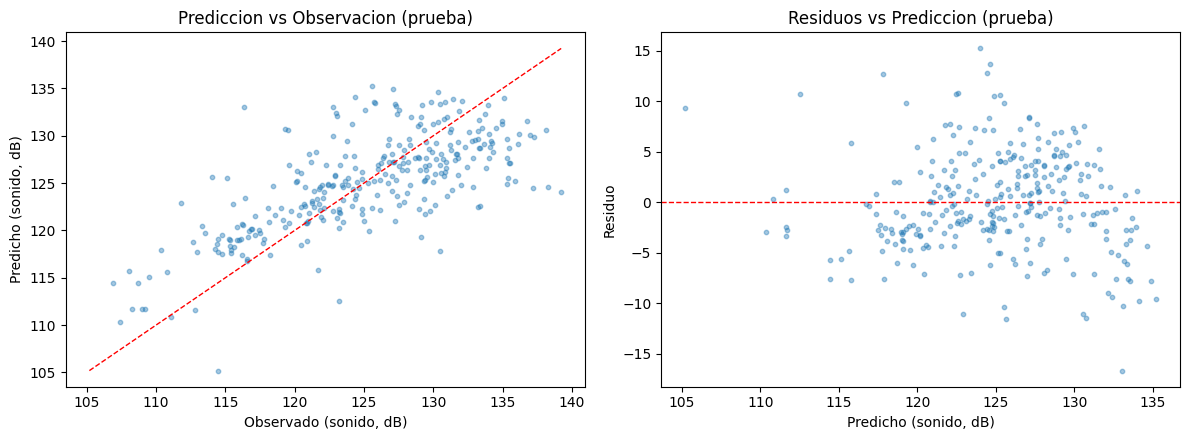


=== ERRORES POR SEGMENTO DE FRECUENCIA (bordes definidos en desarrollo) ===


,count,mean,std,RMSE
segmento_frecuencia,,,,
baja,112,0.2963,5.7469,5.7289
media,102,-0.6591,3.6167,3.6588
alta,87,0.3986,5.0299,5.0167



=== ERRORES POR SEGMENTO DE VELOCIDAD (bordes definidos en desarrollo) ===


,count,mean,std,RMSE
segmento_velocidad,,,,
baja,156,0.0278,5.2802,5.2633
media,57,-0.5471,3.8925,3.8968
alta,88,0.3122,4.8367,4.8193



Nota: estos resultados se reportan sin reajustar ningun modelo. Cualquier error sistematico visible (p. ej. mayor RMSE en el segmento de frecuencia alta) se documenta como limitacion, no se corrige reentrenando.


In [9]:
# ==============================================================================
# PROBLEMA 6c: CONGELAR REPRESENTACION E HIPERPARAMETROS, EVALUACION FINAL UNICA
# ==============================================================================

# --- Congelar decisiones a partir de la seleccion de 6b ---
SELECTED_REPR = best_row["Representacion"]
SELECTED_MODEL = best_row["Modelo"]          # "Ridge" o "Lasso" (el regularizado seleccionado)
SELECTED_LAMBDA = best_row["lambda"]

print(f"Representacion congelada: {SELECTED_REPR}")
print(f"Modelo regularizado congelado: {SELECTED_MODEL} (lambda = {SELECTED_LAMBDA})")

# --- Construir representaciones finales con TODO el desarrollo y TODO prueba ---
X_dev_final, feature_names_final = build_representation(df_dev, repr_type=SELECTED_REPR)
X_test_final, _ = build_representation(df_test, repr_type=SELECTED_REPR)
y_dev_final = df_dev[TARGET].values
y_test_final = df_test[TARGET].values

# Preprocesamiento ajustado UNA SOLA VEZ sobre todo el desarrollo (no sobre prueba)
mu_final, sigma_final = standardize_fit(X_dev_final)
X_dev_s = standardize_apply(X_dev_final, mu_final, sigma_final)
X_test_s = standardize_apply(X_test_final, mu_final, sigma_final)

# --- Ajustar los tres finalistas sobre todo el desarrollo ---
model_reference_mean = y_dev_final.mean()

model_ols_final = LinearRegressionClosedFormNumPy(l2_reg=0.0).fit(X_dev_s, y_dev_final)

if SELECTED_MODEL == "Ridge":
    model_reg_final = LinearRegressionClosedFormNumPy(l2_reg=SELECTED_LAMBDA).fit(X_dev_s, y_dev_final)
elif SELECTED_MODEL == "Lasso":
    model_reg_final = LassoProximalNumPy(l1_reg=SELECTED_LAMBDA, eta=0.01, max_iter=15000, tol=1e-8).fit(X_dev_s, y_dev_final)
else:
    # Si el ganador de 6b fue OLS o la referencia, el "candidato regularizado"
    # se reporta igual como referencia diagnostica, pero no se declara ganador regularizado.
    model_reg_final = model_ols_final

# ==============================================================================
# EVALUACION UNICA SOBRE PRUEBA (no se reajusta nada despues de este punto)
# ==============================================================================

def compute_all_metrics(y_true, y_pred):
    err = y_true - y_pred
    ss_res = np.sum(err ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1.0 - ss_res / ss_tot
    return {
        "MAE": mae(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "R2": r2,
    }

pred_test_reference = np.full_like(y_test_final, fill_value=model_reference_mean)
pred_test_ols = model_ols_final.predict(X_test_s)
pred_test_reg = model_reg_final.predict(X_test_s)

results_test = {
    "Referencia (media)": compute_all_metrics(y_test_final, pred_test_reference),
    "OLS": compute_all_metrics(y_test_final, pred_test_ols),
    f"{SELECTED_MODEL} (lambda={SELECTED_LAMBDA})": compute_all_metrics(y_test_final, pred_test_reg),
}

print("\n=== METRICAS FINALES SOBRE PRUEBA (evaluacion unica) ===")
display(pd.DataFrame(results_test).T)

# --- Graficos de diagnostico (sobre el modelo regularizado seleccionado) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_test_final, pred_test_reg, s=10, alpha=0.4)
lims = [min(y_test_final.min(), pred_test_reg.min()), max(y_test_final.max(), pred_test_reg.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Observado (sonido, dB)")
axes[0].set_ylabel("Predicho (sonido, dB)")
axes[0].set_title("Prediccion vs Observacion (prueba)")

residuals_test = y_test_final - pred_test_reg
axes[1].scatter(pred_test_reg, residuals_test, s=10, alpha=0.4)
axes[1].axhline(0, color="r", linestyle="--", linewidth=1)
axes[1].set_xlabel("Predicho (sonido, dB)")
axes[1].set_ylabel("Residuo")
axes[1].set_title("Residuos vs Prediccion (prueba)")
plt.tight_layout()
plt.show()

# --- Errores por dos segmentos definidos con desarrollo (no con prueba) ---
# Segmento 1: terciles de frecuencia definidos sobre el desarrollo.
# Segmento 2: terciles de velocidad definidos sobre el desarrollo.
freq_edges = np.quantile(df_dev["frecuencia"], [0.0, 1/3, 2/3, 1.0])
vel_edges = np.quantile(df_dev["velocidad"], [0.0, 1/3, 2/3, 1.0])

df_test_seg = df_test.copy()
df_test_seg["pred"] = pred_test_reg
df_test_seg["residuo"] = y_test_final - pred_test_reg
df_test_seg["segmento_frecuencia"] = pd.cut(df_test_seg["frecuencia"], bins=freq_edges,
                                             labels=["baja", "media", "alta"], include_lowest=True)
df_test_seg["segmento_velocidad"] = pd.cut(df_test_seg["velocidad"], bins=vel_edges,
                                            labels=["baja", "media", "alta"], include_lowest=True)

print("\n=== ERRORES POR SEGMENTO DE FRECUENCIA (bordes definidos en desarrollo) ===")
display(df_test_seg.groupby("segmento_frecuencia", observed=True)["residuo"]
        .agg(["count", "mean", "std", lambda s: rmse(s.values, np.zeros_like(s.values))])
        .rename(columns={"<lambda_0>": "RMSE"}))

print("\n=== ERRORES POR SEGMENTO DE VELOCIDAD (bordes definidos en desarrollo) ===")
display(df_test_seg.groupby("segmento_velocidad", observed=True)["residuo"]
        .agg(["count", "mean", "std", lambda s: rmse(s.values, np.zeros_like(s.values))])
        .rename(columns={"<lambda_0>": "RMSE"}))

print("\nNota: estos resultados se reportan sin reajustar ningun modelo. Cualquier error "
      "sistematico visible (p. ej. mayor RMSE en el segmento de frecuencia alta) se documenta "
      "como limitacion, no se corrige reentrenando.")

## Discusión (Problema 6d)

**¿Qué escenario de generalización representa una partición aleatoria de ensayos?**

Una partición aleatoria 80/20 sobre observaciones independientes asume que los ensayos de
prueba provienen de la misma distribución generadora que los de desarrollo — mismo rango
de geometrías de perfil, mismo rango de condiciones de túnel de viento ya explorado en el
experimento original. Representa, por tanto, el escenario de **interpolación dentro del
mismo régimen experimental**: generalización a combinaciones de frecuencia, ángulo, cuerda,
velocidad y espesor no vistas exactamente, pero dentro del mismo espacio de condiciones ya
cubierto por el diseño experimental.

**¿Cómo cambiaría la partición para evaluar condiciones experimentales nuevas?**

Para evaluar extrapolación a condiciones no exploradas (por ejemplo, perfiles con cuerdas
mayores a las observadas, o velocidades fuera del rango del experimento), la partición
debería ser **por bloque de condición experimental** en lugar de aleatoria: reservar como
prueba todos los ensayos de una o varias combinaciones de geometría/velocidad completas,
dejando esas condiciones fuera del desarrollo por completo. Esto evaluaría la capacidad del
modelo de generalizar a un régimen distinto, no solo a nuevas muestras del mismo régimen.
No se afirma que la evaluación aquí realizada ya mida esa capacidad: la partición aleatoria
usada en 6a-6c solo certifica generalización dentro del rango experimental ya cubierto.

**¿Qué evidencia respalda la elección entre OLS, Ridge y Lasso?**

La elección se basa en el RMSE medio de validación cruzada (5 pliegues, semilla 2026),
calculado sobre los mismos pliegues para todos los candidatos, con cada pliegue ajustando
su propio preprocesamiento. El mejor candidato regularizado fue Ridge con λ=0.001
(RMSE medio = 4.7873, desviación estándar entre pliegues = 0.3976), prácticamente empatado
con OLS (RMSE medio = 4.7879). Esta cercanía es en sí misma evidencia relevante: indica que,
para este conjunto de datos (N≈960 en desarrollo, D=5 variables sin colinealidad severa),
la regularización aporta una mejora marginal y no sustancial sobre el estimador sin penalizar.
La representación alternativa (log10(frecuencia) + ángulo×velocidad), aunque motivada por el
EDA, resultó sistemáticamente peor en validación cruzada (RMSE medio ≈4.96 frente a ≈4.79 de
la representación original), por lo que se descartó. La dispersión entre pliegues (std≈0.40)
no se interpreta como un intervalo de confianza formal, solo como una medida descriptiva de
variabilidad bajo este particionamiento específico.

El resultado en prueba confirma la selección: RMSE=4.9013 para Ridge, muy cercano al RMSE
medio de validación cruzada (4.7873, dentro de una desviación estándar de los pliegues),
sin señales de sobreajuste en la elección del hiperparámetro.

**Errores sistemáticos y limitaciones (evidencia de 6c).**

El análisis por segmentos muestra que el error es menor en las condiciones centrales del
rango experimental (RMSE≈3.66 en frecuencia media, RMSE≈3.90 en velocidad media) y mayor en
los extremos (frecuencia baja: RMSE≈5.73; frecuencia alta: RMSE≈5.02; velocidad baja:
RMSE≈5.26; velocidad alta: RMSE≈4.82). Las medias de los residuos por segmento son cercanas
a cero en todos los casos (entre -0.66 y +0.40 dB), lo que indica que el problema es de
**varianza del error**, no de sesgo direccional: el modelo no sobreestima ni subestima
sistemáticamente en ninguna región, pero es menos preciso en los extremos del rango
experimental. Esto es consistente con un R²≈0.50 en prueba y con el hecho de que la
transformación logarítmica de la frecuencia no mejoró el ajuste (6b): la relación verdadera
entre frecuencia/velocidad y el ruido tiene curvatura que un modelo lineal en 5 variables no
resuelve completamente. Esta limitación se documenta como tal, sin reajustar los modelos.

**Advertencia sobre causalidad.**

Las asociaciones encontradas en el EDA (6a) y los coeficientes del modelo final (6b-6c) describen
relaciones estadísticas dentro de los datos observados, bajo las condiciones controladas del
experimento de túnel de viento. No se interpretan como relaciones causales generalizables
fuera de ese diseño experimental específico: por ejemplo, que el coeficiente del ángulo de
ataque sea positivo no implica que aumentar el ángulo *cause* un incremento proporcional del
ruido en cualquier condición no contemplada en este conjunto de datos.